# 04 — Experimentos: o que foi rodado, o que cada rodada ensinou e o que ficou de pé

Atualiza `Relatórios do Projeto/04_EXPERIMENTOS.md` (outubro/2026). Pressupõe os notebooks 01 a 03: o
método está no 03; aqui está o histórico.

## O que mudou desde o relatório de outubro

| Tema | Relatório 04 (14/10/2026) | Agora (10/11/2026) |
|---|---|---|
| Experimentos | smoke test, v1_old e v1 | + v1_corrigido, os diagnósticos do Plano avançado (07/10) e o protocolo de 02/11 (Etapa 1, Etapa 2, 02b, 02c, 02d) |
| Medida principal | R² e MAE no teste de 2025 | **Recall@K** contra baselines, por ano e agrupado, com intervalo e Holm (notebook 03) |
| "TDI é a variável mais importante" | achado consistente nos três notebooks | [REFUTADO] na forma geral: a importância por impureza era diluída pelo trio contábil (P026). Sobrevive restrito: **a árvore depende do TDI de forma separável** |
| Baseline | "falta" | medido: ordenar pelo abandono de *t* bate o acaso em quase todos os anos, e **nenhum modelo supera ordenar pelo abandono de *t*−1** |
| Instabilidade temporal | "questão científica, não bug" | medida: o intervalo de um ano tem largura ~0,30, tão largo quanto a variação; a hipótese de que o modelo ganha nos anos de ruptura foi refutada no EM |
| A transição 2024→2025 | usada como teste nos três notebooks | bloqueada (D7) no protocolo de 02/11, **depois** de já ter sido usada como teste em outubro (§1) |

In [1]:
import sys
from pathlib import Path

AQUI = Path.cwd()                                  # o notebook roda de Dados-do-Projeto/Contexto do Projeto
if not (AQUI / "gerar_tabelas.py").exists():
    raise FileNotFoundError(f"Abra este notebook de dentro de Dados-do-Projeto/Contexto do Projeto (pasta atual: {AQUI})")
DADOS_DO_PROJETO = AQUI.parent
OFICIAL = DADOS_DO_PROJETO / "abandono-escolar"    # junction para Pmonkey/abandono-escolar
GUSTAVO = DADOS_DO_PROJETO / "gustavo"
sys.path.insert(0, str(OFICIAL))
sys.path.insert(0, str(AQUI))

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, Markdown, display

import desenho as D
from src import figuras as F

print(F.conferir_ambiente(OFICIAL / "requirements.txt"))
F.aplicar_estilo()
pd.set_option("display.max_colwidth", 140)
pd.set_option("display.max_columns", 30)
TABELAS = AQUI / "tabelas"                         # python gerar_tabelas.py
FIGURAS = AQUI / "figuras"


def figura_existente(caminho, largura=820):
    """Mostra uma figura gerada por outro notebook (não a recalcula)."""
    F.exigir({caminho.name: caminho}, como_gerar="executar o notebook que a gera (ver a legenda)")
    display(Image(filename=str(caminho), width=largura))

{'pandas': '3.0.5', 'numpy': '2.5.3', 'matplotlib': '3.11.1'}


In [2]:
from matplotlib.patches import Rectangle

REG = AQUI / "registros"
AV = GUSTAVO / "saida" / "avaliacao"
ENTRADAS = {
    "historico": REG / "experimentos_historico.csv",     # escrito à mão, uma linha por experimento, com a fonte
    "matriz": REG / "matriz_experimentos.csv",           # idem, para a matriz E0–E9 da metodologia
    "celulas": AV / "02b_celulas.csv",                   # gustavo/avaliacao/02b_robustez.py
    "padrao": AV / "02b_padrao_temporal.csv",            # idem
    "testes": AV / "02d_testes.csv",                     # gustavo/avaliacao/02d_tdi_separado.py
    "sintese": AV / "sintese_numeros.csv",               # gustavo/avaliacao/sintese_numeros.py
    "associacoes": GUSTAVO / "saida" / "relatorios" / "associacoes_descritivas.csv",  # gustavo/analises/03_associacoes_descritivas.py
}
F.exigir(ENTRADAS, como_gerar="registros/: escritos à mão (README da pasta); os do gustavo/: o script do comentário")
t = {k: pd.read_csv(v, keep_default_na=False) if k in ("historico", "matriz") else pd.read_csv(v)
     for k, v in ENTRADAS.items()}

## 1. Linha do tempo, e o que já tocou a transição 2024→2025

Cada linha é um experimento ou análise; a classificação está em `registros/experimentos_historico.csv`, com a
fonte de cada linha. As duas colunas respondem perguntas diferentes:

- **Testou modelo em 2024→2025:** algum modelo foi ajustado e avaliado com o desfecho de 2025. Isso é o que
  a D7 reserva para "uma única avaliação, depois de congelar tudo".
- **Olhou o desfecho de 2025:** o desfecho entrou em alguma conta, mesmo descritiva.

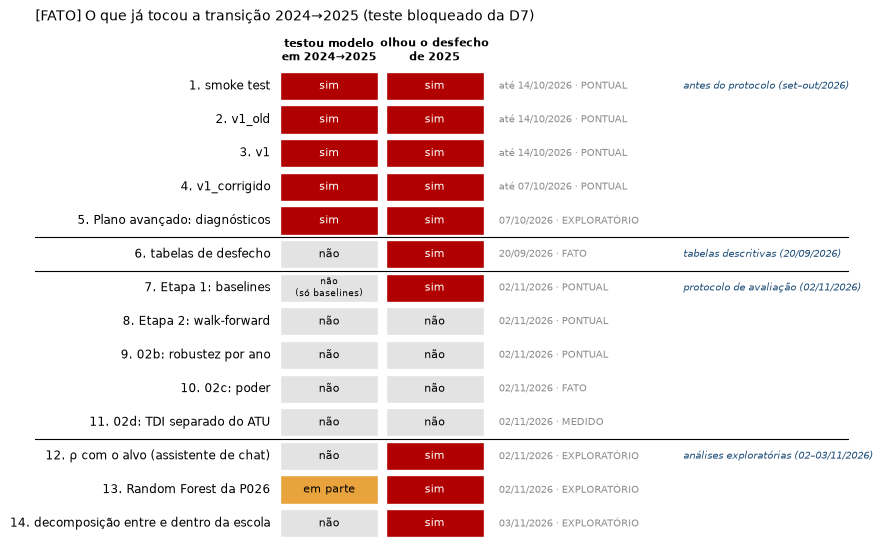

In [3]:
h = t["historico"]
cor = {"sim": D.VERMELHO, "em parte": "#e8a33d", "não": D.CINZA_ESTADO, "não (só baselines)": D.CINZA_ESTADO}
colunas = [("avaliou_modelo_2024_2025", "testou modelo\nem 2024→2025"), ("olhou_desfecho_2025", "olhou o desfecho\nde 2025")]
n = len(h)
fig, ax = plt.subplots(figsize=(10.5, 0.36 * n + 1.6))
for i, r in enumerate(h.itertuples()):
    y = n - 1 - i
    ax.text(-0.08, y + 0.5, f"{r.ordem}. {r.experimento}", ha="right", va="center", fontsize=8.5)
    ax.text(2.95, y + 0.5, f"{r.quando} · {r.nivel}", ha="left", va="center", fontsize=7.5, color=D.CINZA)
    for j, (col, _) in enumerate(colunas):
        v = getattr(r, col)
        ax.add_patch(Rectangle((j * 1.4 + 0.05, y + 0.08), 1.3, 0.84, facecolor=cor[v], edgecolor="white"))
        ax.text(j * 1.4 + 0.7, y + 0.5, v.replace(" (", chr(10) + "("), ha="center", va="center",
                fontsize=8 if "(" not in v else 6.5, color="white" if v == "sim" else "black")
    if i + 1 < n and h["grupo"].iloc[i + 1] != r.grupo:          # separa os grupos de experimentos
        ax.axhline(y, xmin=0, xmax=1, color="black", linewidth=0.8)
for j, (_, rotulo) in enumerate(colunas):
    ax.text(j * 1.4 + 0.7, n + 0.15, rotulo, ha="center", va="bottom", fontsize=8, fontweight="bold")
for g in h["grupo"].unique():                                    # nome do grupo à direita do primeiro item
    primeiro = h.index[h["grupo"] == g][0]
    ax.text(5.4, n - 1 - primeiro + 0.5, g, ha="left", va="center", fontsize=7.5, style="italic", color=D.AZUL)
ax.set_xlim(-3.2, 7.6)
ax.set_ylim(0, n + 1.2)
ax.set_axis_off()
F.titulo(ax, "O que já tocou a transição 2024→2025 (teste bloqueado da D7)", "FATO")
F.salvar(fig, FIGURAS, "04_historico_2024_2025")
plt.show()

**Como ler:**

1. **Antes do protocolo, a transição 2024→2025 serviu de teste.**
   - O smoke test fez um sorteio dentro de ANO_ALVO = 2025.
   - O v1_old testou em 2025; o v1 testou com ANO = 2024.
   - O v1_corrigido tinha um "teste final" com ANO = 2024 → alvo 2025.
   - O próprio Plano avançado (07/10) registra que os diagnósticos dele também a usaram. Ele recomendou
     tratá-la como validação e declarar isso.
2. **O protocolo de 02/11 nunca a usou para avaliar modelo:** o `--incluir-2025` nunca foi passado.
3. **O desfecho de 2025 aparece também em 5 análises descritivas**, já registradas no `CLAUDE.md` §6.

**Divergência com os documentos oficiais.** O `CLAUDE.md` §6 ("Estado da D7"), a metodologia §7.1 e a síntese
§5.3 dizem que a transição "nunca foi usada para avaliar ou selecionar modelo". A frase vale para o protocolo,
não para o projeto. O mesmo vale para a linha proposta P027.

Corrigir esses textos muda o que a pesquisa afirma. Por isso a correção cabe à pesquisadora e ao orientador
(`CLAUDE.md` §6), e o notebook 06 (§5) traz a proposta. A síntese (§3.4) também registra que 2024→2025 é a
transição mais favorável à persistência no AF. Qualquer uso futuro dela como teste precisa declarar as duas
coisas.

In [4]:
h[["ordem", "experimento", "quando", "teste", "resultado", "nivel", "fonte"]].set_index("ordem")

,experimento,quando,teste,resultado,nivel,fonte
ordem,,,,,,
1,smoke test,até 14/10/2026,2024→2025 (aleatório),"R² 0,20 a 0,30; só valida o pipeline",PONTUAL,Relatórios do Projeto/04 §1–3; células 4–7 do notebook
2,v1_old,até 14/10/2026,2024→2025,"R² 0,16 no teste (AF); −0,08 na validação de 2024",PONTUAL,Relatórios do Projeto/04 §4–7
3,v1,até 14/10/2026,2024→2025,"R² 0,18–0,20 (AF) e 0,09–0,12 (EM); inflados pelos 4 problemas",PONTUAL,Relatórios do Projeto/04 §8–11; célula 2 (ano_corte=2024)
4,v1_corrigido,até 07/10/2026,2024→2025 e walk-forward,"segundo o Plano avançado, R² negativo em 2 de 4 dobras (AF) e 3 de 4 (EM); não conferido aqui",PONTUAL,"células 10–20 do notebook; Plano avançado (07/10), p. 1"
5,Plano avançado: diagnósticos,07/10/2026,dobras até 2025,"segundo o plano, a taxa acumulada com encolhimento empata ou supera Random Forest e persistência no MAE",EXPLORATÓRIO,Relatórios do Projeto/Plano avançado do Claude.pdf (o próprio plano declara que usou 2024→2025)
6,tabelas de desfecho,20/09/2026,—,"persistência fraca: Spearman de −0,01 a 0,46; média do ano erra menos que repetir o ano anterior em 9 de 12 transições",FATO,docs/desfechos_distribuicao.csv; docs/desfechos_persistencia.csv
7,Etapa 1: baselines,02/11/2026,17 transições,B1R acima do acaso no Recall@10% em 16 de 16 (AF) e 14 de 16 (EM) até 2024,PONTUAL,01_baselines.csv; síntese §3.4
8,Etapa 2: walk-forward,02/11/2026,2021–2024,regra pontual: bloco 2 'adotado' em 3 de 4 combinações (depois refutado),PONTUAL,02_walkforward.csv; 02_decisoes.csv
9,02b: robustez por ano,02/11/2026,2021–2024,"largura do IC do Recall@10% ~0,30; 66 de 480 diferenças excluem zero (47 contra o B2)",PONTUAL,02b_*.csv; 02b_robustez.md


## 2. Os experimentos de outubro e por que foram substituídos

Números dos notebooks de outubro, como registrados no relatório 04 antigo. São [PONTUAL]: sem intervalo, sem
baseline e, nos três, testados em 2024→2025.

| Experimento | O que mediu | Resultado registrado | Por que não vale como resultado |
|---|---|---|---|
| smoke test | Ridge, RF, HGB; sorteio 80/20 dentro de 2025 | R² 0,20 / 0,25 / 0,30 | sorteio dentro do mesmo ano é muito mais fácil que prever o ano seguinte; só validou o pipeline |
| v1_old | split temporal, AF | R² 0,16 no teste de 2025, −0,08 na validação de 2024 | um único ano de teste; sem baseline; o modelo do AF via variáveis do EM (contraria a D15) |
| v1 | RF e GB, AF e EM | R² 0,18–0,20 (AF), 0,09–0,12 (EM) | os 4 problemas de método (M001): não filtra públicas, imputação quebrada, imputação antes do split, categóricas descartadas |
| v1_corrigido | walk-forward + teste final em 2025 | R² negativo em 2 de 4 dobras (AF) e 3 de 4 (EM), segundo o Plano avançado | sem intervalo nem correção; o teste final usa 2025 |

**O "achado" de outubro: TDI no topo.** Nos três notebooks a importância era por **impureza, coluna a coluna,
com o trio contábil** (aprovação + reprovação + abandono = 100). Isso dilui o rendimento em três colunas
redundantes (P026), então a evidência não sustenta "TDI é a mais importante". O que sobrevive depois da
correção de Holm é mais estreito (§5): a árvore depende do TDI de forma separável.

**A análise crítica de outubro** (relatório gerado por LLM, pago pelo orientador; relatório 04 antigo, §15)
pediu dez passos. Onde cada um está:

| # | Passo pedido | Estado em 10/11 |
|---|---|---|
| 1 | só escolas públicas | feito (universo do protocolo) |
| 2 | corrigir a imputação e usar `Pipeline` | feito (imputação e padronização ajustadas só no treino; teste 04) |
| 3 | incorporar as categóricas | substituído: o modelo não usa categóricas; território e rede ficam no baseline B2 |
| 4 | retirar o vazamento | feito, e ampliado: sem rendimento de *t* (Cenário B), variação defasada |
| 5 | enriquecer (indígena, localização, HAD, IED 2019–2020, Pé-de-Meia) | infraestrutura feita e testada; o resto aguarda decisão ou não foi feito (notebook 07) |
| 6 | baseline de persistência | feito: B0, B1, B1R e **B1R_lag** |
| 7 | walk-forward | feito, 2021–2024 |
| 8 | manter a regressão (MAE, RMSE, R²) | feito, mas só descreve: não decide |
| 9 | classificação (precisão, recall, F1, ROC/PR-AUC) | não feito; o limiar de "alto risco" está em aberto |
| 10 | Recall@20/30/50 | feito de outra forma: K = 10% e 20% das escolas do ano (30% só como sensibilidade) |

## 3. Etapa 1: quanto a persistência acerta, sem modelo

Os baselines rodam na série longa do `gustavo/`. A tabela abaixo é a versão sem 2024→2025, a mesma da
síntese. A figura por transição está no notebook 03, §5.

In [5]:
s = t["sintese"]
s[s["grupo"].str.startswith("Etapa 1 até 2024")][["item", "valor"]].set_index("item")

,valor
item,
AF: transições avaliadas,16 (2009–2024)
AF: anos com MAE B1 < MAE B0,10 de 16
AF: anos com R² B1 > 0,0 de 16
AF: B1R Recall@10% mín / mediana / máx,0.17 / 0.32 / 0.46
AF: anos com B1R Recall@10% > aleatório,16 de 16
AF: B1R Recall@20% mín / mediana / máx,0.28 / 0.42 / 0.49
AF: anos com B1R Recall@20% > aleatório,16 de 16
EM: transições avaliadas,16 (2009–2024)
EM: anos com MAE B1 < MAE B0,5 de 16


**Leitura** [PONTUAL]: como **ordem**, a persistência funciona (acima do acaso em quase todos os anos). Como
**valor**, não: o R² do B1 é negativo em quase todas as transições.

## 4. Etapa 2, ano a ano: os intervalos se sobrepõem

Recall@10% em cada ano de teste, com o intervalo de 95% do bootstrap de escolas daquele ano (`02b`). Aparecem
os dois modelos do bloco 4 (Cenário B) e os quatro baselines:

- **B0** (acaso);
- **B2** (território × rede);
- **B1R_lag** (abandono de *t*−1, a barra);
- **B1R** (abandono de *t*, limite otimista).

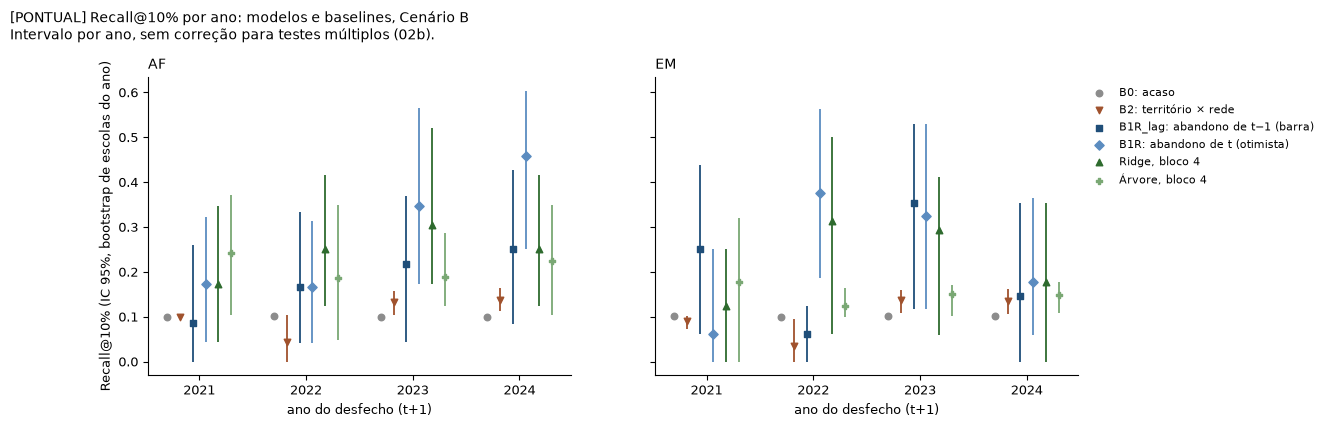

In [6]:
c = t["celulas"]
c = c[c["metrica"] == "Rec@10"]
series = [("B0", "B0: acaso", D.CINZA, "o"), ("B2", "B2: território × rede", "#a0522d", "v"),
          ("B1R_lag", "B1R_lag: abandono de t−1 (barra)", D.AZUL, "s"), ("B1R", "B1R: abandono de t (otimista)", "#5b8cc0", "D"),
          ("B/Ridge b4", "Ridge, bloco 4", "#2e6b2e", "^"), ("B/Árvore b4", "Árvore, bloco 4", "#7aa874", "P")]
desl = dict(zip([s[0] for s in series], [-0.3, -0.18, -0.06, 0.06, 0.18, 0.3]))
fig, axs = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, etapa in zip(axs, ["AF", "EM"]):
    for ident, rotulo, cor_s, marc in series:
        s_ = c[(c["etapa"] == etapa) & (c["id"] == ident)].sort_values("ano_alvo")
        F.pontos(ax, s_["ano_alvo"] + desl[ident], s_["valor"], s_["lo"], s_["hi"], orientacao="v", cor=cor_s,
                 marcador=marc, rotulo=rotulo)
    ax.set_xticks(sorted(c["ano_alvo"].unique()))
    ax.set_title(etapa, loc="left")
    ax.set_xlabel("ano do desfecho (t+1)")
axs[0].set_ylabel("Recall@10% (IC 95%, bootstrap de escolas do ano)")
axs[1].legend(loc="upper left", bbox_to_anchor=(1.0, 1.0), fontsize=8)
F.titulo_figura(fig, "Recall@10% por ano: modelos e baselines, Cenário B", "PONTUAL",
                "Intervalo por ano, sem correção para testes múltiplos (02b).")
fig.subplots_adjust(top=0.82)
F.salvar(fig, FIGURAS, "04_recall_por_ano")
plt.show()

**Leitura:** em cada ano, os intervalos dos modelos e do B1R_lag se cruzam quase inteiros. Com cerca de 235
escolas (AF) e 165 (EM) por ano, um ano não separa nada. Daí o passo seguinte, o **02c**: agrupar as quatro
transições, o que reduz a largura em cerca de metade (notebook 03, §8).

### A hipótese do padrão temporal (refutada no EM)

Hipótese de 02/11, vinda do assistente de chat e repassada pela pesquisadora: "o modelo supera a persistência
nos anos de ruptura (2021, 2022) e perde nos estáveis (2023, 2024)". A figura mostra, para cada combinação, quem
vence o B1R em cada ano.

- **Cor:** a estimativa pontual. **M** = modelo melhor, **B** = B1R melhor, **=** = empate.
- **Texto da célula:** o que o intervalo diz. **?** = o intervalo cruza o zero; uma letra = o intervalo exclui
  o zero a favor de quem ela indica.

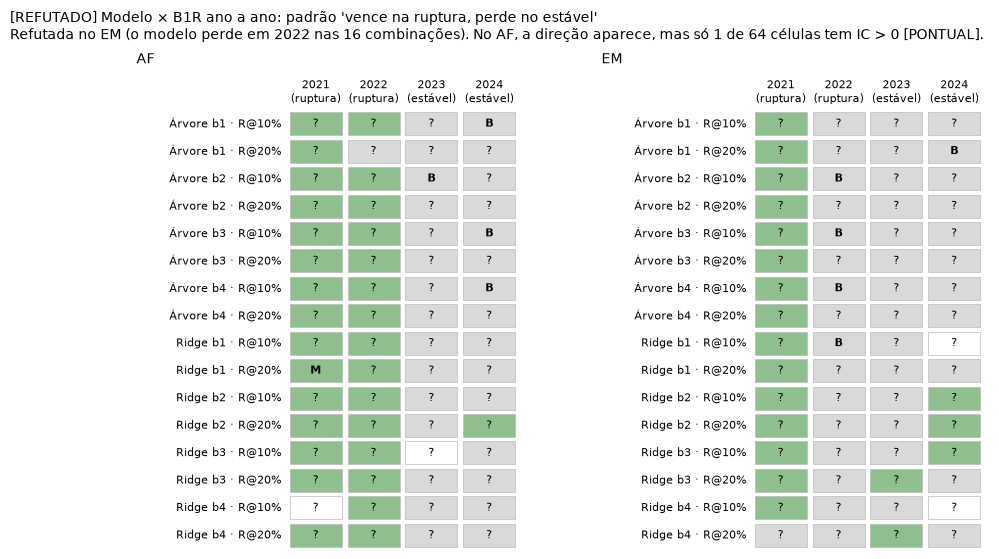

In [7]:
p = t["padrao"]
anos = ["2021", "2022", "2023", "2024"]
cor_p = {"M": "#8fbf8f", "B": "#d9d9d9", "=": "white"}
fig, axs = plt.subplots(1, 2, figsize=(11, 6.2))
for ax, etapa in zip(axs, ["AF", "EM"]):
    s_ = p[p["etapa"] == etapa].reset_index(drop=True)
    for i, r in s_.iterrows():
        y = len(s_) - 1 - i
        modelo = "Ridge" if r["modelo"] == "ridge" else "Árvore"
        ax.text(-0.1, y + 0.5, f"{modelo} b{r['bloco']} · {r['metrica'].replace('Rec@', 'R@')}%", ha="right",
                va="center", fontsize=8)
        for j, (pt, bs) in enumerate(zip(r["pontual 21-22-23-24"], r["bootstrap 21-22-23-24"])):
            ax.add_patch(Rectangle((j + 0.05, y + 0.08), 0.9, 0.84, facecolor=cor_p[pt], edgecolor="#bbbbbb", linewidth=0.5))
            ax.text(j + 0.5, y + 0.5, bs, ha="center", va="center", fontsize=8,
                    fontweight="bold" if bs != "?" else "normal")
    for j, a in enumerate(anos):
        ax.text(j + 0.5, len(s_) + 0.15, a + ("\n(ruptura)" if a in ("2021", "2022") else "\n(estável)"),
                ha="center", va="bottom", fontsize=8)
    ax.set_xlim(-2.6, 4.1)
    ax.set_ylim(0, len(s_) + 1.4)
    ax.set_axis_off()
    ax.set_title(etapa, loc="left")
F.titulo_figura(fig, "Modelo × B1R ano a ano: padrão 'vence na ruptura, perde no estável'", "REFUTADO",
                "Refutada no EM (o modelo perde em 2022 nas 16 combinações). No AF, a direção aparece, mas só 1 de 64 "
                "células tem IC > 0 [PONTUAL].")
F.salvar(fig, FIGURAS, "04_padrao_temporal")
plt.show()

**No AF:**

- a direção aparece (M nos dois primeiros anos, B nos dois últimos) em 12 de 16 combinações;
- quase todas as células têm "?";
- conclusão: **não significativa**.

**No EM:**

- o modelo perde para o B1R em **2022, o ano de pico, em todas as 16 combinações**;
- isso é evidência **contra** o mecanismo, não falta de evidência;
- conclusão: **refutada**.

Em 2024 o EM já está sob o Pé-de-Meia, então 2024 não é "estável" no mesmo sentido do AF.

## 5. Da importância pontual ao teste com correção: o TDI separável (02d)

A Etapa 2 estimou a importância por bloco sem intervalo. O bloco TDI/ATU era o maior em 15 de 16 células
[PONTUAL]. O 02d separou o TDI do ATU e testou as diferenças com bootstrap agrupado (5.000) e Holm. A
família F1 (importância de cada grupo) está na figura `03_importancia_grupos` do notebook 03. Aqui está a
**F2**: o TDI importa mais que o rendimento de *t*−1? E mais que o ATU?

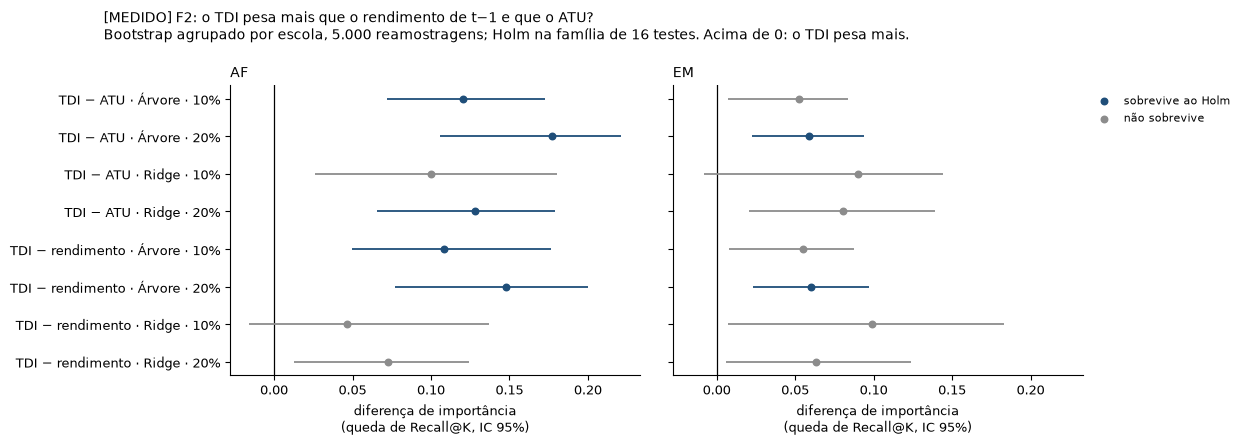

In [8]:
f2 = t["testes"]
f2 = f2[(f2["familia"] == "F2") & f2["primario"]].copy()
f2["rotulo"] = f2["item"] + " · " + f2["modelo"].map({"ridge": "Ridge", "arvore": "Árvore"}) + " · " + f2["K"].str.replace("Rec@", "") + "%"
fig, axs = plt.subplots(1, 2, figsize=(11, 4.2), sharex=True, sharey=True)
for ax, etapa in zip(axs, ["AF", "EM"]):
    s_ = f2[f2["etapa"] == etapa].sort_values(["item", "modelo", "K"])
    F.intervalos(ax, s_["rotulo"], s_["valor"], s_["lo"], s_["hi"], destaque=s_["rejeita_holm"],
                 rotulo_destaque="sobrevive ao Holm", rotulo_resto="não sobrevive")
    ax.set_title(etapa, loc="left")
    ax.set_xlabel("diferença de importância\n(queda de Recall@K, IC 95%)")
axs[1].tick_params(labelleft=False)          # as linhas são as mesmas nas duas etapas
axs[1].legend(loc="upper left", bbox_to_anchor=(1.0, 1.0), fontsize=8)
F.titulo_figura(fig, "F2: o TDI pesa mais que o rendimento de t−1 e que o ATU?", "MEDIDO",
                "Bootstrap agrupado por escola, 5.000 reamostragens; Holm na família de 16 testes. Acima de 0: o TDI pesa mais.")
fig.subplots_adjust(top=0.8, wspace=0.08)
F.salvar(fig, FIGURAS, "04_tdi_separavel")
plt.show()

**Leitura** [MEDIDO]:

- **Na árvore, o TDI é separável do rendimento e do ATU** nas duas etapas: AF nos dois K, EM no K de 20%. No
  Ridge, só TDI − ATU no AF (Recall@20%).
- **Mas usar o TDI não melhora a priorização** em relação a ordenar pelo abandono de *t*−1 (F5: 0 de 56). O
  instrumento mostra que o modelo **usa** o TDI, não que o TDI **acrescenta** poder de priorização à
  persistência.

## 6. As análises descritivas que corrigiram hipóteses (análise 03)

Três afirmações de 02/11 foram testadas com números reproduzidos por código
(`gustavo/analises/03_associacoes_descritivas.py`, conferido pelo teste 05, com 36 checks).

**(a) "Atributos permanentes predizem mal"** [REFUTADO]. Quanto cada medida se repete de um ano para o
seguinte:

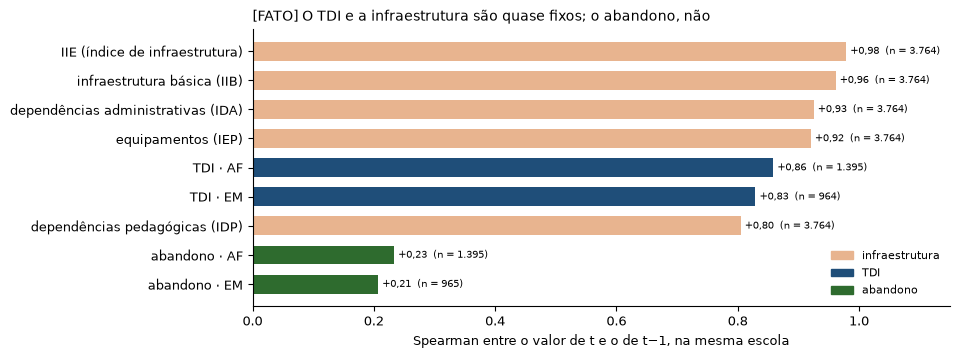

In [9]:
a = t["associacoes"]
A = a[(a["bloco"] == "A") & (a["metodo"] == "spearman")].copy()
nomes = {"TDI(t) x TDI(t-1)": "TDI", "ABANDONO(t) x ABANDONO(t-1)": "abandono",
         "IIE_zano(t) x IIE_zano(t-1)": "IIE (índice de infraestrutura)",
         "DIM_IIB_zano(t) x DIM_IIB_zano(t-1)": "infraestrutura básica (IIB)",
         "DIM_IDA_zano(t) x DIM_IDA_zano(t-1)": "dependências administrativas (IDA)",
         "DIM_IDP_zano(t) x DIM_IDP_zano(t-1)": "dependências pedagógicas (IDP)",
         "DIM_IEP_zano(t) x DIM_IEP_zano(t-1)": "equipamentos (IEP)"}
A = A[A["medida"].isin(nomes)]
A["rotulo"] = A["medida"].map(nomes) + A["etapa"].map(lambda e: "" if e == "escola" else f" · {e}")
A["grupo"] = A["medida"].map(lambda m: "infraestrutura" if ("IIE" in m or "DIM" in m) else ("TDI" if "TDI" in m else "abandono"))
A = A.sort_values("valor")
cores_g = {"infraestrutura": "#e8b48f", "TDI": D.AZUL, "abandono": "#2e6b2e"}
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.barh(A["rotulo"], A["valor"], color=[cores_g[g] for g in A["grupo"]], height=0.65)
for i, (v, n_) in enumerate(zip(A["valor"], A["n"])):
    ax.annotate(f"{v:+.2f}".replace(".", ",") + f"  (n = {n_:,})".replace(",", "."), (v, i), xytext=(3, 0),
                textcoords="offset points", va="center", fontsize=7.5)
ax.set_xlim(0, 1.15)
ax.set_xlabel("Spearman entre o valor de t e o de t−1, na mesma escola")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c_, label=g) for g, c_ in cores_g.items()], loc="lower right", fontsize=8)
F.titulo(ax, "O TDI e a infraestrutura são quase fixos; o abandono, não", "FATO")
F.salvar(fig, FIGURAS, "04_persistencia_preditores")
plt.show()

O TDI (~0,85) e a infraestrutura (0,80 a 0,98) são quase fixos de um ano para o outro, e o abandono (~0,25)
não.

- O modelo **depende do TDI**.
- A infraestrutura, igualmente permanente, **não prediz**.

Logo, o que separa os dois não é a estabilidade: é **o que medem**. O TDI mede a trajetória dos alunos; a
infraestrutura, o prédio. Essa é a leitura registrada no `DECISOES.md` [INTERPRETAÇÃO].

**(b) De onde vem a associação do TDI com o abandono do ano seguinte** [EXPLORATÓRIO, usa o desfecho de todos
os anos, inclusive 2025]:

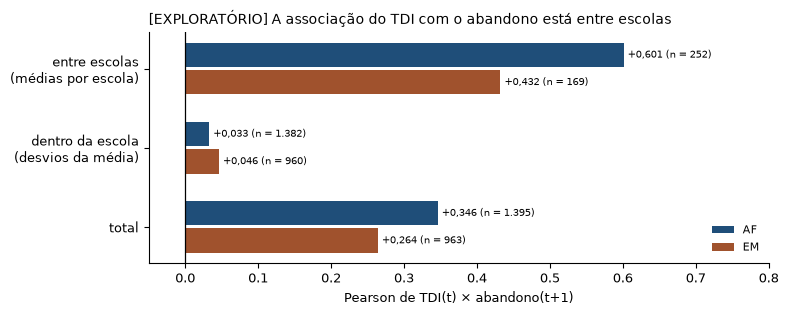

In [10]:
Dd = a[(a["bloco"] == "D") & a["medida"].str.startswith("TDI(t) x abandono(t+1)")].copy()
Dd["parte"] = Dd["medida"].str.extract(r":\s*(entre escolas|dentro da escola|total)")[0]
ordem = ["entre escolas", "dentro da escola", "total"]
fig, ax = plt.subplots(figsize=(8, 3))
for k, etapa in enumerate(["AF", "EM"]):
    s_ = Dd[Dd["etapa"] == etapa].set_index("parte").loc[ordem]
    y = [i * 2.6 + k * 0.9 for i in range(len(ordem))]
    ax.barh(y, s_["valor"], height=0.8, color=D.AZUL if etapa == "AF" else "#a0522d", label=etapa)
    for yi, v, n_ in zip(y, s_["valor"], s_["n"]):
        ax.annotate(f"{v:+.3f}".replace(".", ",") + f" (n = {n_:,})".replace(",", "."), (max(v, 0), yi), xytext=(3, 0),
                    textcoords="offset points", va="center", fontsize=7.5)
ax.set_yticks([i * 2.6 + 0.45 for i in range(len(ordem))], ["entre escolas\n(médias por escola)",
              "dentro da escola\n(desvios da média)", "total"])
ax.invert_yaxis()
F.linha_zero(ax)
ax.set_xlim(-0.05, 0.8)
ax.set_xlabel("Pearson de TDI(t) × abandono(t+1)")
ax.legend(fontsize=8, loc="lower right")
F.titulo(ax, "A associação do TDI com o abandono está entre escolas", "EXPLORATÓRIO")
F.salvar(fig, FIGURAS, "04_decomposicao_tdi")
plt.show()

Escolas com TDI mais alto têm mais abandono (+0,60 no AF, +0,43 no EM, nas médias por escola). Mas, **dentro
da mesma escola**, um ano de TDI mais alto não vem seguido de mais abandono (+0,03 e +0,05). O TDI funciona
como uma **marca da escola**, não como um sinal que sobe antes do abandono. Isso é compatível com o modelo
depender do TDI sem superar o abandono de *t*−1.

**(c) "TDI no topo é artefato da diluição do trio"** [REFUTADO] (P026; Random Forest exploratório, AF,
n = 1.390, 3 sementes):

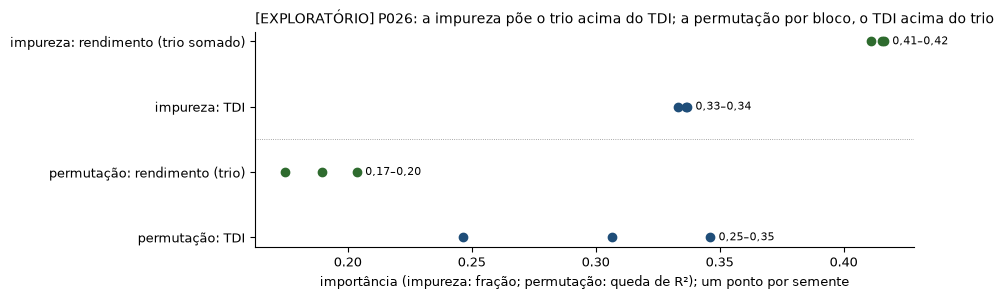

In [11]:
C = a[a["bloco"] == "C"].copy()
pares = [("MDI com trio: trio somado", "impureza: rendimento (trio somado)", "#2e6b2e"),
         ("MDI com trio: TDI", "impureza: TDI", D.AZUL),
         ("permutação de bloco: rendimento (trio)", "permutação: rendimento (trio)", "#2e6b2e"),
         ("permutação de bloco: TDI", "permutação: TDI", D.AZUL)]
fig, ax = plt.subplots(figsize=(8.5, 2.8))
for i, (prefixo, rotulo, cor_c) in enumerate(pares):
    v = C[C["medida"].str.startswith(prefixo)]["valor"]
    ax.scatter(v, [len(pares) - 1 - i] * len(v), color=cor_c, s=36, zorder=3)
    ax.annotate(f"{v.min():.2f}–{v.max():.2f}".replace(".", ","), (v.max(), len(pares) - 1 - i), xytext=(6, 0),
                textcoords="offset points", va="center", fontsize=8)
ax.set_yticks(range(len(pares))[::-1], [p_[1] for p_ in pares])
ax.axhline(1.5, color=D.CINZA, linewidth=0.6, linestyle=":")
ax.set_xlabel("importância (impureza: fração; permutação: queda de R²); um ponto por semente")
F.titulo(ax, "P026: a impureza põe o trio acima do TDI; a permutação por bloco, o TDI acima do trio", "EXPLORATÓRIO")
F.salvar(fig, FIGURAS, "04_p026_impureza_permutacao")
plt.show()

A diluição existe: somando o trio, a importância por impureza passa a do TDI. Mas, **permutando o bloco
inteiro**, o TDI continua acima do rendimento. Daí a regra de 02/11: importância só por permutação de grupo,
nunca por coluna nem por impureza. A conclusão de outubro ("TDI no topo") não era só artefato, mas a forma que
sobrevive à correção é a restrita da §5.

## 7. A matriz de experimentos da metodologia (E0–E9)

O plano de experimentos da metodologia (§8), escrito em setembro a partir da proposta do orientador, e onde
cada um está. A classificação e a fonte estão em `registros/matriz_experimentos.csv`.

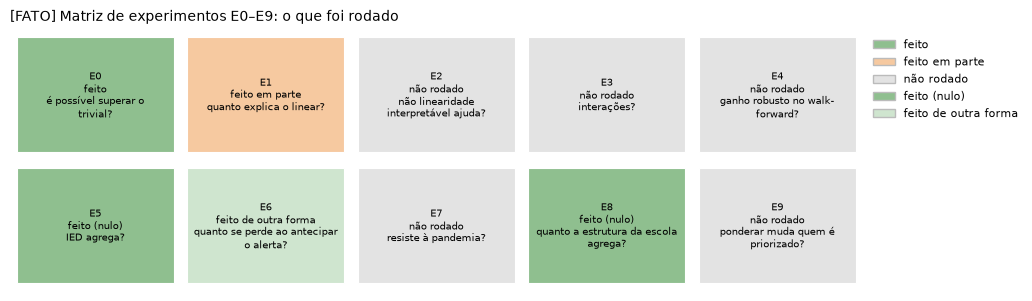

,pergunta,estado,o_que_foi_feito,fonte
exp,,,,
E0,é possível superar o trivial?,feito,"Etapa 1 (B0, B1, B1R; 2009–2025) e Etapa 2 (B0, B1R, B1R_lag, B2; 2021–2024)",01_baselines.csv; 02_walkforward.csv
E1,quanto explica o linear?,feito em parte,"só Ridge com α = 1 fixo (sem L1, sem busca de α); a logística B4 não foi implementada",síntese §5.4
E2,não linearidade interpretável ajuda?,não rodado,—,síntese §5.4
E3,interações?,não rodado,"no protocolo só há a árvore rasa (profundidade 3); Random Forest só no exploratório da P026, sem divisão temporal",síntese §3.6 e §5.4
E4,ganho robusto no walk-forward?,não rodado,—,síntese §5.4
E5,IED agrega?,feito (nulo),"bloco 3 (IED N1..N5) e família F3 nas transições com IED no treino: 0 de 8; ausência de evidência, não evidência de ausência",02d_testes.csv; DECISOES.md 2026-11-02
E6,quanto se perde ao antecipar o alerta?,feito de outra forma,o Cenário B virou o principal; a comparação A × B ficou só pontual (A não superou B no Ridge do bloco 1),síntese §3.4
E7,resiste à pandemia?,não rodado,sensibilidade S1–S4 da D6 pendente,síntese §5.5
E8,quanto a estrutura da escola agrega?,feito (nulo),infraestrutura (18 itens → 4 dimensões + IIE) no bloco 4: 0 de 8 testes na F1; sai do modelo e fica como estratificação,DECISOES.md 2026-11-02


In [12]:
m = t["matriz"]
fig, ax = plt.subplots(figsize=(11, 3.4))
D.grade_estados(ax, m["exp"], m["estado"], colunas=5, notas=m["pergunta"], tamanho=8.5)
F.titulo(ax, "Matriz de experimentos E0–E9: o que foi rodado", "FATO")
F.salvar(fig, FIGURAS, "04_matriz_experimentos")
plt.show()
m.set_index("exp")[["pergunta", "estado", "o_que_foi_feito", "fonte"]]

**O protocolo de 02/11 andou de lado em relação à matriz.**

- Rodou o E0 completo e testou os blocos que correspondem ao E5 (IED) e ao E8 (infraestrutura), os dois com
  resultado nulo.
- Trocou "qual modelo é melhor" (E1–E4) por "qual bloco carrega sinal", com dois modelos simples fixos.
- Ficaram sem rodar os modelos mais flexíveis (E2–E4), a sensibilidade da pandemia (E7) e o peso por matrícula
  (E9).

## 8. O que foi refutado

Treze afirmações feitas durante o projeto caíram diante dos dados (síntese §4, com o registro de cada uma):

| # | Afirmação refutada | O que derrubou |
|---|---|---|
| 1 | "TDI no topo é artefato da diluição do trio" | permutação por bloco (§6c) e F2 na árvore (§5) |
| 2 | "O modelo supera a persistência nos anos de ruptura" | EM: perde em 2022 em 16 de 16; AF: 1 de 64 células com IC > 0 (§4) |
| 3 | "O modelo supera o B1R_lag no AF" | bootstrap por ano e agrupado com Holm: F5 0 de 56 |
| 4 | "TDI e rendimento defasado carregam a mesma informação" | no máximo ~13% de variância compartilhada |
| 5 | "Atributos permanentes predizem mal" | TDI e infraestrutura são igualmente permanentes; só o TDI prediz (§6a) |
| 6 | "No EM, intervalo acima de zero contra o B2 em 6 de 8" | vale só em K = 30% e sem correção; com Holm, 1 de 16 |
| 7 | "O bloco TDI/ATU carrega sinal" | separados, o ATU tem 0 de 12; o sinal é do TDI |
| 8 | "Bloco 2 adotado em 3 de 4 combinações" | 0 de 32 diferenças com IC que exclui zero |
| 9 | "2007–2018 não tem verificação contra a fonte" | conferido 19 de 19 anos em 14/10, na máquina do Gustavo; o certo é "não reverificável nesta máquina" |
| 10 | "2024→2025 é o único ano que ninguém olhou" | 5 usos descritivos (e, antes do protocolo, os testes dos notebooks de outubro, §1) |
| 11 | "TDI é a variável mais importante" (outubro) | evidência inválida (importância por coluna, com o trio) |
| 12 | "Mapeamento posicional fixo entre gerações do tx_rend" | `tap_F58` muda de significado entre 2015–17 e 2018–20 |
| 13 | "Base do Censo validada" (14/10, de manhã) | água, banheiro e projetor zerados em 2019–2021 por colunas mantidas sem coleta |

## 9. Estado científico

| | Em outubro (relatório 04, §20) | Agora |
|---|---|---|
| **Demonstrado** | "existe sinal preditivo"; "TDI é a variável mais associada"; "o pipeline funciona" | **[MEDIDO]** no AF, a informação da própria escola ordena melhor que território × rede (B2); a árvore depende do TDI de forma separável, nas duas etapas. **[FATO]** o instrumento, como está, não separa os blocos entre si nem do abandono de *t*−1 (largura ~0,30 por ano) |
| **Não demonstrado** | robustez entre anos, comparação com baseline, ganho operacional, generalização para 2026 | **[MEDIDO, nulo]** nenhum modelo supera ordenar pelo abandono de *t*−1 (F5: 0 de 56); nenhum bloco supera o anterior; ATU, IED e infraestrutura sem sinal. Nunca testados: modelos flexíveis, S1–S4, equidade por estrato, classificação, peso por matrícula |
| **Próximo passo** | "corrigir o pipeline e congelar a metodologia" | feito em 02/11. O que falta agora é **poder estatístico** e as decisões do notebook 07 |